# AIML Project

***

## Project Title

**ARES** -  Adaptive Reinforcement-based Endpoint Security

***

## Project Description

**ARES (Adaptive Reinforcement-based Endpoint Security)** is an intelligent endpoint security system designed to detect and prevent evolving cyber threats. It uses machine learning and adaptive techniques to identify QR-code phishing (quishing). The system analyzes threats in real time and assigns risk levels to potentially harmful activities. ARES can alert users, block malicious content, and continuously improve its detection based on previous threat patterns. The primary focus is on QR-code phishing.

***

## Team Members


| Sl. No. | Name                         | USN          |
|---------|------------------------------|--------------|
| 1       | Aryan S Jain                  | 1RUA25CSE0087 |
| 2       | Ashwin Chandrashekar Naik     | 1RUA25CSE0090 |
| 3       | Ashwin Rajesha Bhat           | 1RUA25CSE0091 |
| 4       | Ashwin Subramaniam            | 1RUA25CSE0092 |

***

## Phase 01: Loading the dataset

Load the dataset 'phishing_features.csv'.

***

In [17]:
from pathlib import Path
import pandas as pd

# Find the repository root whether this notebook is launched from the root
# folder or from the notebooks/ folder in VS Code or Codespaces.
CURRENT_DIR = Path.cwd().resolve()
REPO_ROOT = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (path / "data").is_dir() and (path / "results").is_dir()),
    CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
)
DATA_DIR = REPO_ROOT / "data"
MODELS_DIR = REPO_ROOT / "models"
RESULTS_DIR = REPO_ROOT / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = DATA_DIR / "phishing_features.csv"
if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH}. Put phishing_features.csv in the repository's data/ folder."
    )

df = pd.read_csv(DATASET_PATH)
print(f"Repository root: {REPO_ROOT}")
print(f"Loaded dataset: {DATASET_PATH} ({len(df):,} rows)")


Repository root: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security
Loaded dataset: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/data/phishing_features.csv (160,064 rows)


## Phase 02: Data Interpretation

### Step 2.1

Preview the first 10 records.

***

In [18]:
df.head(10)

,url,label,url_length,num_dots,has_https,has_ip,num_subdirs,num_params,suspicious_words,tld,special_char_count,digits_count,entropy
0,http://forum.uk.securebankinggroup.com/107519/...,1,89,3,0,0,5,0,2,com,4,29,4.792985
1,http://b45042.com/fish/29,1,25,1,0,0,4,0,0,com,0,7,4.003856
2,http://bet73018.com/lottery/99,1,30,1,0,0,4,0,0,com,0,7,4.053236
3,https://logiin--metsa-autho.webflow.io/,1,39,2,1,0,3,0,0,io,3,0,4.150411
4,https://mettamasklogiiann.webflow.io/,1,37,2,1,0,3,0,0,io,0,0,4.100817
5,http://bet73018.com/lottery/134,1,31,1,0,0,4,0,0,com,0,8,4.063563
6,https://metamasklogenies.webflow.io/,1,36,2,1,0,3,0,0,io,0,0,4.086049
7,https://mmettamaskilogin.webflow.io/,1,36,2,1,0,3,0,1,io,0,0,4.086049
8,https://www.robiox.com.py/users/322503287968/p...,1,52,3,1,0,5,0,0,py,0,12,4.582383
9,https://xbancobhd2025xxxxxxxxx.xo.je/,1,37,2,1,0,3,0,0,je,0,4,3.728139


### Step 2.2

List the column names.

***

In [19]:
df.columns.tolist()

['url',
 'label',
 'url_length',
 'num_dots',
 'has_https',
 'has_ip',
 'num_subdirs',
 'num_params',
 'suspicious_words',
 'tld',
 'special_char_count',
 'digits_count',
 'entropy']

### Step 2.3

Check the dataset dimensions.

***

In [20]:
df.shape

(160064, 13)

### Step 2.4

Inspect column data types.

***

In [21]:
df.dtypes

url                       str
label                   int64
url_length              int64
num_dots                int64
has_https               int64
has_ip                  int64
num_subdirs             int64
num_params              int64
suspicious_words        int64
tld                       str
special_char_count      int64
digits_count            int64
entropy               float64
dtype: object

### Step 2.5

Review the datset structure & non-null counts.

***

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160064 entries, 0 to 160063
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   url                 160064 non-null  str    
 1   label               160064 non-null  int64  
 2   url_length          160064 non-null  int64  
 3   num_dots            160064 non-null  int64  
 4   has_https           160064 non-null  int64  
 5   has_ip              160064 non-null  int64  
 6   num_subdirs         160064 non-null  int64  
 7   num_params          160064 non-null  int64  
 8   suspicious_words    160064 non-null  int64  
 9   tld                 159243 non-null  str    
 10  special_char_count  160064 non-null  int64  
 11  digits_count        160064 non-null  int64  
 12  entropy             160064 non-null  float64
dtypes: float64(1), int64(10), str(2)
memory usage: 15.9 MB


### Step 2.6

Count missing values in each column.

***

In [23]:
mv_count = df.isnull().sum()
print(mv_count)

url                     0
label                   0
url_length              0
num_dots                0
has_https               0
has_ip                  0
num_subdirs             0
num_params              0
suspicious_words        0
tld                   821
special_char_count      0
digits_count            0
entropy                 0
dtype: int64


### Step 2.7

Count all missing value cells.

***

In [24]:
missing_values_cells = mv_count.sum()

print(missing_values_cells)

821


### Step 2.8

Calculate missing value cells percentage.

***

In [25]:
mv_percentage = (df.isnull().mean() * 100).round(2)
print(mv_percentage)

url                   0.00
label                 0.00
url_length            0.00
num_dots              0.00
has_https             0.00
has_ip                0.00
num_subdirs           0.00
num_params            0.00
suspicious_words      0.00
tld                   0.51
special_char_count    0.00
digits_count          0.00
entropy               0.00
dtype: float64


### Step 2.9

Build a missing value report.

***

In [26]:
mv_report = pd.DataFrame({
    "Count of Missing Values": mv_count,
    "Missing Values %": mv_percentage
})

print(mv_report)

                    Count of Missing Values  Missing Values %
url                                       0              0.00
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_subdirs                               0              0.00
num_params                                0              0.00
suspicious_words                          0              0.00
tld                                     821              0.51
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


### Step 2.10

Sort the missing value report.

***

In [27]:
sorted_mv_report = mv_report.sort_values(by = "Count of Missing Values", ascending = False)

print(sorted_mv_report)

                    Count of Missing Values  Missing Values %
tld                                     821              0.51
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
url                                       0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_params                                0              0.00
num_subdirs                               0              0.00
suspicious_words                          0              0.00
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


### Step 2.11

Show only columns with missing values.

***

In [28]:
print(sorted_mv_report[sorted_mv_report["Count of Missing Values"] > 0])

     Count of Missing Values  Missing Values %
tld                      821              0.51


### Step 2.12

Identify target label.

***

In [29]:
target_column = "label"

unique_labels = df[target_column].unique()

print(unique_labels)

[1 0]


### Step 2.13

Count records in target column.

***

In [30]:
uv_count = df[target_column].value_counts()

print(uv_count)

label
1    159244
0       820
Name: count, dtype: int64


### Step 2.14

Calculate class proportions.

***

In [31]:
uv_percentage = df[target_column].value_counts(normalize = True).mul(100).round(2)

print(uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


### Note

We can observe that the dataset has a major class imbalance the two labels.

***

## Phase 03: Data Preprocessing

### Step 3.1

Visualize the class distribution.

***

In [38]:
import matplotlib.pyplot as plt

def generate_bar_graph(y, title, x_label, y_label):
    y.plot(kind = "bar")

    plt.title(title)

    plt.xlabel(x_label)

    plt.ylabel(y_label)

    plt.show()

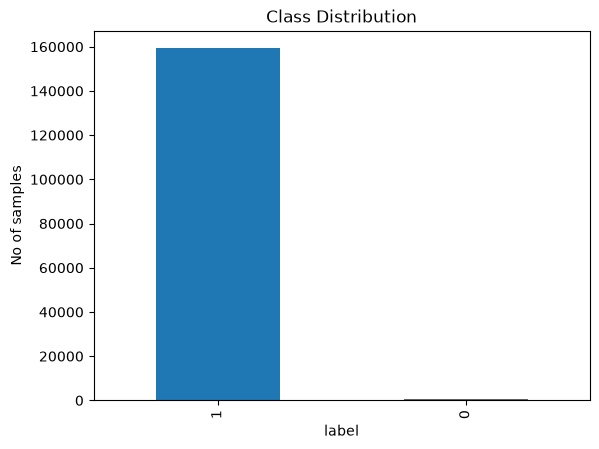

In [39]:
generate_bar_graph(uv_count, "Class Distribution", target_column, "No of samples")

### Step 3.2

Create an initial train-test split for the model.

***

In [40]:
from sklearn.model_selection import train_test_split

X = df.drop(columns = [target_column])
y = df[target_column]

# Use a fixed seed and stratification so the severe class imbalance is represented consistently in both splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = 42, stratify = y
)

### Step 3.3

Check the dimensions of the initial training & testing sets.

***

In [41]:
print("Training set:", X_train.shape, y_train.shape)

Training set: (128051, 12) (128051,)


In [42]:
print("Testing set:", X_test.shape, y_test.shape)

Testing set: (32013, 12) (32013,)


### Step 3.4

Calculate the initial proportions of the training & testing sets.

***

In [43]:
training_uv_percentage = y_train.value_counts(normalize = True).mul(100).round(2)

print(training_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [44]:
testing_uv_percentage = y_test.value_counts(normalize = True).mul(100).round(2)

print(testing_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


### Step 3.5

Select the numerical features & create a secondary train-test split.

***

In [45]:
numerical_feature_columns = [
    "url_length", "num_dots", "has_https", "has_ip", "num_subdirs",
    "num_params", "suspicious_words", "special_char_count", "digits_count", "entropy"
]

missing_columns = [column for column in [target_column, *numerical_feature_columns] if column not in df.columns]
if missing_columns:
    raise KeyError(f"Dataset is missing required columns: {missing_columns}")
if df[target_column].isna().any():
    raise ValueError(f"Target column '{target_column}' contains missing labels.")
if set(pd.Series(df[target_column]).unique()) != {0, 1}:
    raise ValueError(f"Expected binary labels 0 and 1; found {sorted(pd.Series(df[target_column]).unique())}.")

X = df[numerical_feature_columns].copy()
y = df[target_column].astype(int)
if X.isna().any().any():
    missing_features = X.columns[X.isna().any()].tolist()
    raise ValueError(f"Selected model features contain missing values: {missing_features}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


### Step 3.6

Check the dimensions of the secondary training & testing sets.

***

In [46]:
print("Training set:", X_train.shape, y_train.shape)

Training set: (128051, 10) (128051,)


In [47]:
print("Testing set:", X_test.shape, y_test.shape)

Testing set: (32013, 10) (32013,)


### Step 3.7

Calculate the initial proportions of the secondary training & testing sets.

***

In [48]:
training_uv_percentage = y_train.value_counts(normalize = True).mul(100).round(2)

print(training_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [49]:
testing_uv_percentage = y_test.value_counts(normalize = True).mul(100).round(2)

print(testing_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


***

### Note

It can be observed that my dataset has major class imbalance.

We shall resolve this issue using:
- The **Class Weights** method

***

## Phase 04: Model Development & Training

### Step 4.1

Train a class-weighted model.

***

In [50]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1
)

### Step 4.2

Visualize the distribution.

***

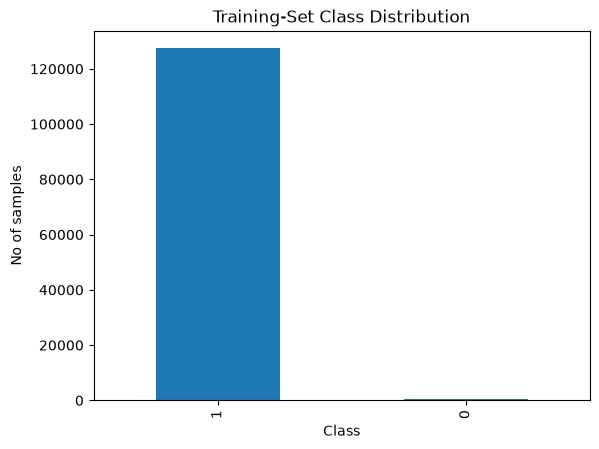

In [51]:
generate_bar_graph(y_train.value_counts(), "Training-Set Class Distribution", "Class", "No of samples")

### Step 4.3

Train the machine-learning model.

***

In [52]:
model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

### Step 4.4

Evaluate the predicted values on training data and probability of class 1.

***

In [53]:
y_train_predicted = model.predict(X_train)

print(y_train_predicted)

[1 1 1 ... 1 1 1]


In [54]:
y_train_probability = model.predict_proba(X_train)

print(y_train_probability)

[[0. 1.]
 [0. 1.]
 [0. 1.]
 ...
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [55]:
c1_train_probability = y_train_probability[:, 1]

print(c1_train_probability)

[1. 1. 1. ... 1. 1. 1.]


### Step 4.5

Generate a Confusion matrix on the training data.

***

In [56]:
from sklearn.metrics import confusion_matrix

cm_train = confusion_matrix(y_train, y_train_predicted, labels = [0, 1])

print(cm_train)

[[   656      0]
 [     0 127395]]


In [57]:
from sklearn.metrics import ConfusionMatrixDisplay

def generate_confusion_matrix(confusion_matrix, labels, color, title, values_format):
    display = ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = labels);

    # Use integer counts so the matrix is easier to interpret.
    display.plot(cmap = color, values_format = values_format)

    plt.title(title)
    plt.show()

### Step 4.6

Visualize the Confusion matrix on the training data.

***

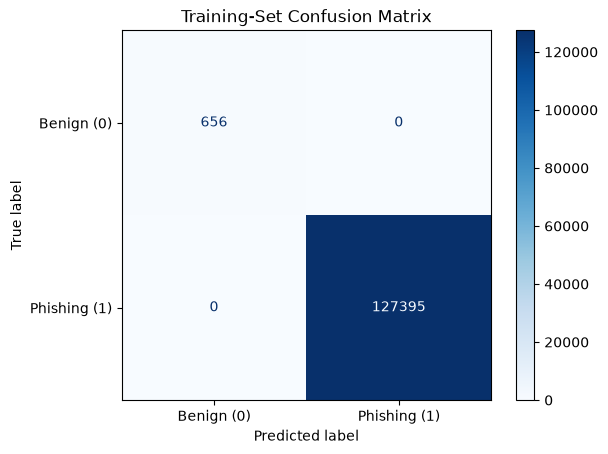

In [58]:
generate_confusion_matrix(cm_train, ["Benign (0)", "Phishing (1)"], "Blues", "Training-Set Confusion Matrix", "d")

### Step 4.7

Create a classification report on the training dataset.

***

In [59]:
from sklearn.metrics import classification_report

# Summarize per-class precision, recall, and F1-score.
cr_train = classification_report(y_train, y_train_predicted)

print(cr_train)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       656
           1       1.00      1.00      1.00    127395

    accuracy                           1.00    128051
   macro avg       1.00      1.00      1.00    128051
weighted avg       1.00      1.00      1.00    128051



### Step 4.8

Calculate the accuracy, balanced accuracy, precision, average precision, recall, and F1-score on the training dataset, rounded to 4 decimals

***

In [60]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, average_precision_score, recall_score, f1_score
)

# Report both conventional and imbalance-aware metrics; zero_division=0 prevents errors when a class is absent from predictions.
def evaluate_metrics(y, y_predicted, c1_probability, label, division):
    accuracy = accuracy_score(y, y_predicted)

    balanced_accuracy = balanced_accuracy_score(y, y_predicted)

    precision = precision_score(y, y_predicted, pos_label = label, zero_division = division)
    
    avg_precision = average_precision_score(y, c1_probability)

    recall = recall_score(y, y_predicted, pos_label = label, zero_division = division)

    f1 = f1_score(y, y_predicted, pos_label = label, zero_division = division)

    return accuracy, balanced_accuracy, precision, avg_precision, recall, f1

In [61]:
def display_metrics(set_type, accuracy, balanced_accuracy, precision, avg_precision, recall, f1_score, round_off):
    print(f"{set_type} Set Metric Values:\n\nAccuracy = {round(accuracy, round_off)}\n")
    print(f"Balanced Accuracy = {round(balanced_accuracy, round_off)}\n")
    print(f"Precision = {round(precision, round_off)}\n")
    print(f"Average Precision = {round(avg_precision, round_off)}\n")
    print(f"Recall = {round(recall, round_off)}\n")
    print(f"F1-score = {round(f1_score, round_off)}")

In [62]:
accuracy_train, balanced_accuracy_train, precision_train, avg_precision_train, recall_train, f1_score_train = evaluate_metrics(
    y_train, y_train_predicted, c1_train_probability, 1, 0
)

display_metrics("Training", accuracy_train, balanced_accuracy_train, precision_train, avg_precision_train, recall_train, f1_score_train, 4)

Training Set Metric Values:

Accuracy = 1.0

Balanced Accuracy = 1.0

Precision = 1.0

Average Precision = 1.0

Recall = 1.0

F1-score = 1.0


### Step 4.9

Repeat steps from 4.4 to 4.8 for the testing data

***

In [63]:
y_test_predicted = model.predict(X_test)

print(y_test_predicted)

[0 1 1 ... 1 1 1]


In [64]:
y_test_probability = model.predict_proba(X_test)

print(y_test_probability)

[[1. 0.]
 [0. 1.]
 [0. 1.]
 ...
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [65]:
c1_test_probability = y_test_probability[:, 1]

print(c1_test_probability)

[0. 1. 1. ... 1. 1. 1.]


In [66]:
cm_test = confusion_matrix(y_test, y_test_predicted, labels = [0, 1])

print(cm_test)

[[  164     0]
 [    0 31849]]


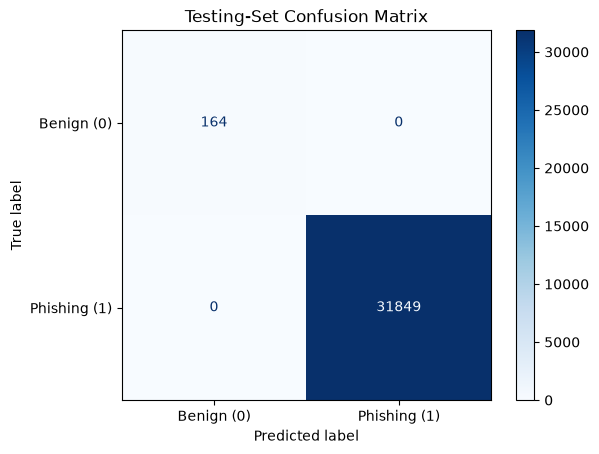

In [67]:
generate_confusion_matrix(cm_test, ["Benign (0)", "Phishing (1)"], "Blues", "Testing-Set Confusion Matrix", "d")

In [68]:
cr_test = classification_report(y_test, y_test_predicted)

print(cr_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       164
           1       1.00      1.00      1.00     31849

    accuracy                           1.00     32013
   macro avg       1.00      1.00      1.00     32013
weighted avg       1.00      1.00      1.00     32013



In [69]:
accuracy_test, balanced_accuracy_test, precision_test, avg_precision_test, recall_test, f1_score_test = evaluate_metrics(
    y_test, y_test_predicted, c1_test_probability, 1, 0
)

display_metrics("Test", accuracy_test, balanced_accuracy_test, precision_test, avg_precision_test, recall_test, f1_score_test, 4)

Test Set Metric Values:

Accuracy = 1.0

Balanced Accuracy = 1.0

Precision = 1.0

Average Precision = 1.0

Recall = 1.0

F1-score = 1.0


### Step 4.10

Save the trained model as a joblib file

***

In [70]:
import joblib

model_bundle = {
    # Saving the trained ML model object as model
    "model": model,
    # Saving the numerical feature column names as features
    "features": numerical_feature_columns,
    # Saving the label encoding
    "label_mapping": {
        0: "Benign",
        1: "Phishing"
    }
}

In [71]:
print(numerical_feature_columns)

['url_length', 'num_dots', 'has_https', 'has_ip', 'num_subdirs', 'num_params', 'suspicious_words', 'special_char_count', 'digits_count', 'entropy']


In [72]:
import joblib
MODEL_PATH = MODELS_DIR / "model.joblib"
joblib.dump(model_bundle, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")


Model saved to: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/models/model.joblib


## Evaluation 01

We achieved perfect classification on the held-out test split. Subsequent dataset diagnostics revealed systematic representation differences between the benign and phishing classes, including URL scheme presence, path-separator counts, and TLD missingness. These differences may enable shortcut learning and limit generalization. Therefore, the initial score is treated as a preliminary dataset-specific result rather than evidence of perfect real-world phishing detection.

***

### Reasons for Evaluation 01

- The phishing URLs and the benign URLs have different sources. Because they have different sources, they follow different URL patterns, making the classes easier to separate.

- The dataset relies on numerical features such as suspicious_words, has_ip, url_length, and entropy, which are legitimate but do not persist in new attacks.
  
- The testing set may not be sufficiently independent since both the training and testing sets may have samples from the same data-generating process. The random forest classifier addresses this.
  
- Information not available when analyzing a genuinely new URL might get leaked. The feature-generation logic needs to be inspected to address this.

***

### Step 4.11

Record a trustworthy baseline.

***

In [73]:
def record_baseline(
    model, seed, name, y, label, accuracy, balanced_accuracy, precision, recall, f1_score, avg_precision, round_off, cm, cr
):
    metrics = {
        "model_name": model,
        "random_seed": seed,
        "dataset_split": name,
        "n_samples": len(y),
        "positive_class": label,
        "accuracy": round(accuracy, round_off),
        "balanced_accuracy": round(balanced_accuracy, round_off),
        "precision_positive": round(precision, round_off),
        "recall_positive": round(recall, round_off),
        "f1_positive": round(f1_score, round_off),
        "average_precision": round(avg_precision, round_off),
        "confusion_matrix": cm.tolist(),
        "classification_report": cr
    }

    return metrics

In [74]:
baseline_train = record_baseline(
    "Baseline model", 
    42, 
    "train", 
    y_train, 
    1, 
    accuracy_train, 
    balanced_accuracy_train, 
    precision_train, 
    recall_train, 
    f1_score_train, 
    avg_precision_train, 
    4, 
    cm_train, 
    cr_train
)

In [75]:
baseline_test = record_baseline(
    "Baseline model", 
    42, 
    "test", 
    y_test, 
    1, 
    accuracy_test, 
    balanced_accuracy_test, 
    precision_test, 
    recall_test, 
    f1_score_test, 
    avg_precision_test, 
    4, 
    cm_test, 
    cr_test
)

### Step 4.12

Save the baselines as .json files

***

In [76]:
baseline_record = {
    "baseline": {
        "train": baseline_train,
        "test": baseline_test
    },
    "dataset_limitations": [
        "The dataset may not represent the full population or future production data.",
        "Class imbalance may make accuracy misleading; balanced accuracy, recall, F1, and average precision are also reported.",
        "The train/test split is a single split; results may vary with a different random seed or cross-validation fold.",
        "The baseline uses only the features available in this dataset and may omit important predictive variables.",
        "Predictions should not be used for high-stakes decisions without domain review, fairness checks, and monitoring."
    ]
}

In [78]:
import json
from pathlib import Path

# Define RESULTS_DIR if not defined earlier
if 'RESULTS_DIR' not in globals():
    if Path("/kaggle/working").exists():
        RESULTS_DIR = Path("/kaggle/working")
    elif Path("results").exists():
        RESULTS_DIR = Path("results")
    else:
        RESULTS_DIR = Path("../results")
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_PATH = RESULTS_DIR / "baseline.json"
with BASELINE_PATH.open("w", encoding="utf-8") as file:
    json.dump(baseline_record, file, indent=4)
print(f"Baseline metrics saved to: {BASELINE_PATH}")

Baseline metrics saved to: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/results/baseline.json


### Step 4.13

Record a baseline metadata file

***

In [79]:
import sklearn

metadata = {
    "model_name": type(model).__name__,
    "model_file": str(MODEL_PATH.relative_to(REPO_ROOT)),
    "framework": "scikit-learn",
    "sklearn_version": sklearn.__version__,
    "random_seed": 42,
    "task": "binary_classification",
    "positive_class": 1,
    "feature_names": model.feature_names_in_.tolist(),
    "n_features": len(model.feature_names_in_.tolist()),
    "training_samples": len(X_train),
    "dataset_limitations": [
        "The dataset may not represent the full population or future production data.",
        "Class imbalance may make accuracy misleading; balanced accuracy, recall, F1, and average precision should also be considered.",
        "The train/test split is a single split; results may vary with a different random seed or cross-validation setup.",
        "The model uses only the features available in this dataset and may omit important predictive variables.",
        "Predictions should not be used for high-stakes decisions without domain review, fairness checks, and monitoring."
    ]
}


### Step 4.14

Save the metadata as a JSON file

***

In [80]:
METADATA_PATH = RESULTS_DIR / "metadata.json"
with METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)
print(f"Metadata saved to: {METADATA_PATH}")


Metadata saved to: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/results/metadata.json


## Phase 05: QR-Code Decoder & Encoder

### Step 5.1

Identify the pickle files containing the labels and the images

***

In [81]:
import pickle

# These Kaggle pickle datasets are optional and are not part of the listed
# GitHub repository structure. Set their paths here if you have downloaded them.
QR_IMAGES_PATH = DATA_DIR / "qr_codes_29.pickle"
QR_LABELS_PATH = DATA_DIR / "qr_codes_29_labels.pickle"

qr_dataset_available = QR_IMAGES_PATH.is_file() and QR_LABELS_PATH.is_file()
if qr_dataset_available:
    with QR_IMAGES_PATH.open("rb") as file:
        X_qr = pickle.load(file)
    with QR_LABELS_PATH.open("rb") as file:
        y_qr = pickle.load(file)
    if len(X_qr) != len(y_qr):
        raise ValueError(
            f"QR image/label count mismatch: {len(X_qr)} images and {len(y_qr)} labels."
        )
    print(f"Loaded {len(X_qr):,} QR images and labels.")
else:
    print("Skipping QR-image inspection: optional pickle files were not found.")
    print(f"Expected image file: {QR_IMAGES_PATH}")
    print(f"Expected label file: {QR_LABELS_PATH}")


Skipping QR-image inspection: optional pickle files were not found.
Expected image file: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/data/qr_codes_29.pickle
Expected label file: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/data/qr_codes_29_labels.pickle


In [82]:
if qr_dataset_available:
    X_type = type(X_qr)
    y_type = type(y_qr)

    X_shape = getattr(X, "shape", f"length = {len(X_qr)}")
    y_shape = getattr(y_qr, "shape", f"length = {len(y)}")

    X_dtype = getattr(X, "dtype", None)
    y_dtype = getattr(y_qr, "dtype", None)

    Y = y_qr[:10] if hasattr(y, "__getitem__") else y

In [83]:
if qr_dataset_available:
    print(f"Types:\nX: {X_type}\ny: {y_type}\n")
    print(f"Shapes:\nX: {X_shape}\ny: {y_shape}\n")
    print(f"Data Types:\nX: {X_dtype}\ny: {y_dtype}")

### Step 5.2

Verify label encoding in the datasets

***

In [84]:
if qr_dataset_available:
    import numpy as np

    # Convert labels to a NumPy array so NumPy aggregation functions can be used.
    Y = np.asarray(y_qr)

    Y_unique = np.unique(Y)
    Y_count = dict(zip(*np.unique(Y, return_counts = True)))
    Y_classes = len(Y_unique)

In [85]:
if qr_dataset_available:
    print("Unique labels:", Y_unique)
    print("Counts:", Y_count)
    print("No of classes:", Y_classes)

### Step 5.3

Confirm image encoding on the datasets

***

In [86]:
if qr_dataset_available:
    print("Shape =", X_shape)
    print("Data type =", X_dtype)
    print("Xmin =", X_qr.min()); print("Xmax =", X_qr.max())
    print("Xmean =", X_qr.mean()); print("Xstd =", X_qr.std())

In [87]:
if qr_dataset_available:
    X_values, X_counts = np.unique(X_qr, return_counts = True)
    print("First 10 values = ", X_values[:10])
    print("Last 10 values = ", X_values[-10:])

In [88]:
if qr_dataset_available:
    X_length = len(X_values)

    X_max = X_qr.max()

    if X_length <= 2:
        print("Binary image")

    elif X_length <= 256 and X_max <= 255:
        print("Grayscale image")

    elif X_max >= 256:
        print("int16 but values > 255. Therefore, check scaling/source encoding")

    else:
        print(X_length, "distinct values. Therefore, inspect further")

### Step 5.4

Use a sample dataset

***

In [89]:
if qr_dataset_available:
    sample_indices = [i for i in [0, 1, 100, 5000, 9000] if i < len(X_qr)]

    for index in sample_indices:
        image = X_qr[index]

        print(f"{index}. Label = {y_qr[index]}\tShape = {image.shape}")
        print(f"\tMinimum = {image.min()}\tMaximum = {image.max()}\tMean = {image.mean():.2f}")
        print(f"\tUnique = {len(np.unique(image))}")

### Step 5.5

Generate the QR Code figure for the first benign and phishing labels

***

In [90]:
if qr_dataset_available:
    # Select the first benign and phishing samples for visual inspection.
    benign_index = int(np.where(y_qr == 0)[0][0])
    phishing_index = int(np.where(y_qr == 1)[0][0])

In [91]:
if qr_dataset_available:
    import matplotlib.pyplot as plt

    # Show one benign and one phishing QR code side by side for a visual sanity check.
    figure, axes = plt.subplots(1, 2, figsize = (7, 3.5))

    for axis, index, name in zip(axes, [benign_index, phishing_index], ["label = 0", "label = 1"]):
        axis.imshow(X_qr[index], cmap = "gray")
        axis.set_title(f"{index}. {name}")

        # Pixel coordinates are not meaningful for QR inspection.
        axis.axis("off")

    plt.tight_layout()
    plt.show()

### Step 5.6

Generate a Pixel Value Histogram

***

In [92]:
if qr_dataset_available:
    # Cell 68
    plt.figure(figsize = (6, 3))

    plt.hist(X_qr.ravel(), bins = 50)

    plt.title("Pixel value distribution")
    plt.xlabel("Pixel value")
    plt.ylabel("Count")

    plt.show()

### Step 5.7

Extract the URL from the QR Code

***

In [93]:
if qr_dataset_available:
    # Convert dataset images to uint8, the format OpenCV expects.
    def image_to_uint8(image):
        image = np.asarray(image)

        # Boolean images use True/False, so map them to 255/0 for OpenCV.
        if image.dtype == bool:
            return (image.astype(np.uint8)) * 255

        if image.dtype == np.uint8:
            return image

        else:
            image = image.astype(np.float32)

            minimum, maximum = float(image.min()), float(image.max())
            difference = maximum - minimum

            # Return a black image when the input has virtually no contrast, since normalization would divide by zero.
            if difference < 1e-9:
                return np.zeros_like(image, dtype = np.uint8)

            image = (image - minimum) / difference

            return (image * 255).astype(np.uint8)

In [94]:
if qr_dataset_available:
    try:
        import cv2
    except ImportError:
        print("Skipping QR decoding: OpenCV is not installed. Install opencv-python to enable this cell.")
    else:
        detector = cv2.QRCodeDetector()

        for index in [benign_index, phishing_index]:
            image = image_to_uint8(X_qr[index])
            # Add a white quiet zone so the QR detector can identify the code boundary.
            padded_image = cv2.copyMakeBorder(image, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)
            # Enlarge small QR images because detection may fail at their original resolution.
            enlarged_image = cv2.resize(padded_image, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
            data, coordinates, straightened_image = detector.detectAndDecode(enlarged_image)
            print(f"{index}. Label = {y_qr[index]} Decoded = {data!r}")


## Phase 06: Dataset Bias & Shortcut Diagnostics

### Overview

Inspect systematic representation differences between the benign and phishing classes in the baseline dataset.

***

### Step 6.1

Compare URL scheme presence, engineered feature distributions, and missing TLD rates across labels.

***

In [95]:
# ARES: Investigate dataset shortcuts. Run only when the relevant source columns exist.
if "url" not in df.columns:
    print("Skipping URL-scheme analysis: the dataset has no 'url' column.")
else:
    has_scheme = df["url"].astype("string").str.match(r"^https?://", case=False, na=False)
    print("URL scheme presence by label:")
    print(pd.crosstab(df["label"], has_scheme, rownames=["Label"], colnames=["Has HTTP/HTTPS scheme"]))

features_to_check = [c for c in ["url_length", "num_subdirs", "has_https", "num_dots", "digits_count"] if c in df.columns]
if features_to_check:
    print("\nFeature ranges by label:")
    print(df.groupby("label")[features_to_check].agg(["min", "median", "max"]))
else:
    print("Skipping feature-range analysis: none of the selected feature columns are present.")

if "tld" in df.columns:
    print("\nMissing TLD percentage by label:")
    print(df.groupby("label")["tld"].apply(lambda s: round(s.isna().mean() * 100, 2)))
else:
    print("Skipping TLD analysis: the dataset has no 'tld' column.")

if "num_subdirs" in df.columns:
    print("\nnum_subdirs distribution by label:")
    print(pd.crosstab(df["label"], df["num_subdirs"]))


URL scheme presence by label:
Has HTTP/HTTPS scheme  False   True 
Label                               
0                        820       0
1                          0  159244

Feature ranges by label:
      url_length               num_subdirs             has_https             \
             min median    max         min median  max       min median max   
label                                                                         
0              6   16.0     22           0    0.0    0         0    0.0   0   
1             12   37.0  25523           2    3.0  104         0    0.0   1   

      num_dots            digits_count               
           min median max          min median   max  
label                                                
0            1    1.0   2            0    1.0     3  
1            1    3.0  59            0   12.0  3413  

Missing TLD percentage by label:
label
0    100.0
1      0.0
Name: tld, dtype: float64

num_subdirs distribution by label:
num_su

### Step 6.2

Export a sample slice of the test split for model verification.

***

In [96]:
# Export a small reproducible test sample, limited to the rows actually available.
sample_indices = [i for i in [0, 1, 2, 10, 100] if i < len(X_test)]
TEST_SAMPLE_PATH = RESULTS_DIR / "test_sample.csv"
X_test.iloc[sample_indices].to_csv(TEST_SAMPLE_PATH, index=False)
print(f"Saved {len(sample_indices)} test rows to: {TEST_SAMPLE_PATH}")


Saved 5 test rows to: /workspaces/02-Adaptive-Reinforcement-based-Endpoint-Security/results/test_sample.csv
